# Lecture 7 — Exercises 1-4: Linear Regression with One Variable

Adapted from the Machine Learning Specialization labs by Andrew Ng (DeepLearning.AI and Stanford Online).

Before you start, save your own copy with File > Save a copy in Drive.

Complete the lines marked `# TODO` and run the cells from top to bottom. After each exercise, the cell marked `# Check your result` prints `Check passed` when your code gives the expected numbers.

<a name="1"></a>
## 1 - Packages

First, let's run the cell below to import all the packages that you will need in this notebook.
- [NumPy](https://numpy.org) is the fundamental package for working with matrices in Python.
- [matplotlib](https://matplotlib.org) is the library we use to plot graphs in Python.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import copy
import math
%matplotlib inline

In [2]:
import numpy as np


def load_data():
    """
    Loads houses.txt. Column 0 is the size in square feet and column 4 is the price in $1,000.
    The file has no header line, so all 100 houses are read.
    It tries the copy in the course repository on GitHub first and then the file
    data/houses.txt in the folder where the notebook runs. In Colab that folder is /content.
    """
    url = "https://raw.githubusercontent.com/andresmasegosa/MI_E26/main/lecture07/data/houses.txt"
    local_file = "data/houses.txt"
    try:
        data = np.loadtxt(url, delimiter=',')
        source = "GitHub"
    except Exception:
        try:
            data = np.loadtxt(local_file, delimiter=',')
            source = local_file
        except Exception:
            raise FileNotFoundError(
                "Could not load houses.txt from GitHub or from data/houses.txt. "
                "Check your internet connection, or put houses.txt in a folder called data "
                "in the folder where the notebook runs. In Colab, upload it to /content/data.") from None
    print(f"Loaded {data.shape[0]} houses from {source}")

    X = data[:,0]/1000.0
    y = data[:,4]
    return X, y

## 2 - Problem Statement

We will use the motivating example of housing price prediction. The training set contains 100 houses, each with its size and its selling price.

We would like to build a linear regression model that uses the size to predict the price of other houses, for example a house of 1,200 sqft.

## 3 - Dataset

You will start by loading the dataset for this task.
- The `load_data()` function defined above loads the data into the variables `x_train` and `y_train`.
  - `x_train` is the size of each house, in 1,000 sqft.
  - `y_train` is the price of each house, in thousands of dollars.
  - Both `x_train` and `y_train` are NumPy arrays.

In [3]:
# load the dataset
x_train, y_train = load_data()

Loaded 100 houses from GitHub


#### View the variables
Before starting on any task, it is useful to get more familiar with your dataset.  
- A good place to start is to just print out each variable and see what it contains.

The two cells below print the type of `x_train` and `y_train` and their first five elements.

In [4]:
# print x_train
print("Type of x_train:",type(x_train))
print("First five elements of x_train are:\n", x_train[:5])

Type of x_train: <class 'numpy.ndarray'>
First five elements of x_train are:
 [0.952 1.244 1.947 1.725 1.959]


In [5]:
# print y_train
print("Type of y_train:",type(y_train))
print("First five elements of y_train are:\n", y_train[:5])

Type of y_train: <class 'numpy.ndarray'>
First five elements of y_train are:
 [271.5 300.  509.8 394.  540. ]


#### Check the dimensions of your variables

Another useful way to get familiar with your data is to view its dimensions.

The cell below prints the shape of `x_train` and `y_train` and the number of training examples $m$.

In [6]:
print ('The shape of x_train is:', x_train.shape)
print ('The shape of y_train is: ', y_train.shape)
print ('Number of training examples (m):', len(x_train))

The shape of x_train is: (100,)
The shape of y_train is:  (100,)
Number of training examples (m): 100


#### Visualize your data

The cell below draws each house as a red cross, with its size on the horizontal axis and its price on the vertical axis.

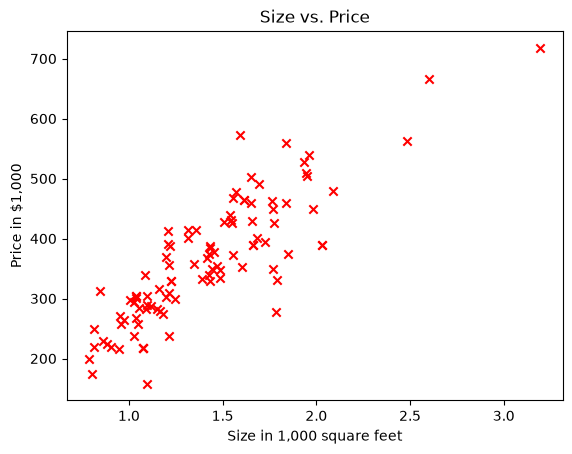

In [7]:
# Create a scatter plot of the data. To change the markers to red "x",
# we used the 'marker' and 'c' parameters
plt.scatter(x_train, y_train, marker='x', c='r')

# Set the title
plt.title("Size vs. Price")
# Set the y-axis label
plt.ylabel('Price in $1,000')
# Set the x-axis label
plt.xlabel('Size in 1,000 square feet')
plt.show()

## 4 - Model function

As described in the lecture, the model for linear regression is a function that maps an input $x$ to a prediction $\hat{y}$. For the example $x^{(i)}$ the prediction is

$$ f_{w,b}(x^{(i)}) = wx^{(i)} + b $$

The formula above describes a straight line. Different values of $w$ and $b$ give different straight lines on the plot.

In the maths we number the training examples from 1 to $m$, so $x^{(1)}$ is the first house and $x^{(m)}$ is the last one. Python counts from 0, so $x^{(i)}$ is `x_train[i-1]`.

Now, let's compute the value of $f_{w,b}(x^{(i)})$ for each house. You can explicitly write this out for each house as

for $x^{(1)}$, `f_wb = w * x[0] + b`

for $x^{(2)}$, `f_wb = w * x[1] + b`

<a name="ex01"></a>
### Exercise 1: Model Function

Complete the function `compute_model_output` to compute the output of a linear regression model given a vector of $x$ values and the two parameters $w$ and $b$.

> The argument description `(ndarray (m,))` describes a NumPy array of shape (m,). `(scalar)` describes an argument that is a single number.
>
> `np.zeros(m)` returns a one-dimensional NumPy array with $m$ entries, all equal to zero.

In [8]:
def compute_model_output(x, w, b):
    """
    Computes the prediction of a linear model
    Args:
      x (ndarray (m,)): Data, m examples
      w,b (scalar)    : model parameters
    Returns
      f_wb (ndarray (m,)): model predictions
    """

    m = x.shape[0]
    f_wb = np.zeros(m)
    for i in range(m):
        f_wb[i] = w * x[i] + b

    return f_wb

In [9]:
# Check your result
tmp_f_wb = compute_model_output(x_train, 100, 10)
assert tmp_f_wb is not None, "compute_model_output returns None. Complete the line marked TODO first."
assert not np.isnan(tmp_f_wb).any(), "compute_model_output gives NaN. Complete the line marked TODO first."
print("First three predictions with w=100, b=10:", tmp_f_wb[:3])
assert np.allclose(tmp_f_wb[:3], [105.2, 134.4, 204.7]), "compute_model_output gives wrong predictions on the houses"
assert np.allclose(compute_model_output(np.array([1.0, 2.5]), 100, 10), [110.0, 260.0]), "compute_model_output gives wrong predictions for x = (1, 2.5)"
print("Check passed")

First three predictions with w=100, b=10: [105.2 134.4 204.7]
Check passed


Expected output:

    First three predictions with w=100, b=10: [105.2 134.4 204.7]
    Check passed

The second check uses two sizes you can do by hand. With $w = 100$ and $b = 10$, a house of 1,000 sqft ($x = 1$) gets the prediction 110 and a house of 2,500 sqft ($x = 2.5$) gets 260, in thousands of dollars.

Now let's call the `compute_model_output` function and plot the output.

The cell below sets $w = 100$ and $b = 10$, and the cell after it draws that line on the data.

You can come back to the cell below later to change the values of $w$ and $b$.

In [10]:
w = 100
b = 10
print(f"w: {w}")
print(f"b: {b}")

w: 100
b: 10


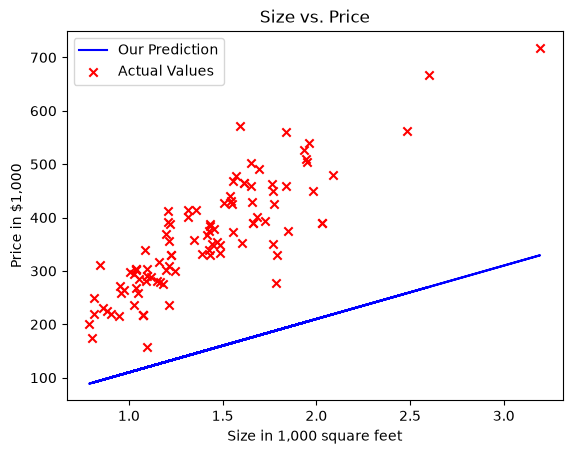

In [11]:
tmp_f_wb = compute_model_output(x_train, w, b)

# Plot our model prediction
plt.plot(x_train, tmp_f_wb, c='b',label='Our Prediction')

# Plot the data points
plt.scatter(x_train, y_train, marker='x', c='r',label='Actual Values')

# Set the title
plt.title("Size vs. Price")
# Set the y-axis label
plt.ylabel('Price in $1,000')
# Set the x-axis label
plt.xlabel('Size in 1,000 square feet')
plt.legend()
plt.show()

As you can see, setting $w = 100$ and $b = 10$ does *not* result in a line that fits our data.

Try other values of $w$ and $b$ in the cell that sets them, and run the plot cell again. Which values give a line that fits the data? Gradient descent finds them for you in Exercise 4.

<a name="5"></a>
## 5 - Compute Cost

The cost $J(w,b)$ is one number that says how well the line with parameters $w$ and $b$ fits the training set. A smaller cost means a better fit.
- In this section you write a function that computes $J(w,b)$.
- Gradient descent, in Section 6, changes $w$ and $b$ step by step to make the cost smaller. This function lets you check that the cost goes down.

#### Cost function
As you may recall from the lecture, for one variable, the cost function for linear regression $J(w,b)$ is defined as

$$J(w,b) = \frac{1}{2m} \sum\limits_{i = 1}^{m} (f_{w,b}(x^{(i)}) - y^{(i)})^2$$

- You can think of $f_{w,b}(x^{(i)})$ as the model's prediction of the price of house $i$, as opposed to $y^{(i)}$, which is the actual price recorded in the data.
- $m$ is the number of training examples in the dataset

#### Model prediction

- For linear regression with one variable, the prediction of the model $f_{w,b}$ for an example $x^{(i)}$ is represented as

$$ f_{w,b}(x^{(i)}) = wx^{(i)} + b$$

This is the equation for a line, with an intercept $b$ and a slope $w$.

<a name="ex02"></a>
### Exercise 2: Cost Function

Complete the two lines marked `# TODO` inside the loop of `compute_cost`. For each example $i$:

* `fwb_i` is the prediction of the model, $f_{w,b}(x^{(i)}) = wx^{(i)} + b$,
* `cost_i` is the squared error of that example, $(f_{w,b}(x^{(i)}) - y^{(i)})^2$.

The loop adds the squared errors in `cost_sum`. The division by $2m$ after the loop is given. Do not divide inside the loop. The function then returns

$$J(w,b) = \frac{1}{2m} \sum\limits_{i = 1}^{m} (f_{w,b}(x^{(i)}) - y^{(i)})^2$$

In [12]:
def compute_cost(x, y, w, b):
    """
    Computes the cost function for linear regression.

    Args:
        x (ndarray): Shape (m,) Input to the model (size of each house in 1,000 sqft)
        y (ndarray): Shape (m,) Target (price of each house in $1,000)
        w, b (scalar): Parameters of the model

    Returns
        total_cost (float): The cost of using w,b as the parameters for linear regression
               to fit the data points in x and y
    """
    # number of training examples
    m = x.shape[0]

    cost_sum = 0
    for i in range(m):
        fwb_i = w * x[i] + b
        cost_i = (fwb_i - y[i]) ** 2
        cost_sum = cost_sum + cost_i

    total_cost = cost_sum/(2*m)

    return total_cost

Run the cell below to test your function. If a line marked `# TODO` still holds `None`, Python stops with a `TypeError` about `NoneType`.

In [13]:
# Compute cost with some initial values for parameters w, b
initial_w = 100
initial_b = 10

cost = compute_cost(x_train, y_train, initial_w, initial_b)
assert np.ndim(cost) == 0, "compute_cost returns an array, but J(w,b) is one number. Inside the loop, use x[i] and y[i], not x and y."
print(type(cost))
print(f'Cost at w={initial_w}, b={initial_b}: {cost:.3f}')

<class 'numpy.float64'>
Cost at w=100, b=10: 24822.672


Expected output:

    <class 'numpy.float64'>
    Cost at w=100, b=10: 24822.672

In [14]:
# Check your result
tmp_cost = compute_cost(x_train, y_train, 100, 10)
assert tmp_cost is not None, "compute_cost returns None. Complete the lines marked TODO first."
assert np.ndim(tmp_cost) == 0, "compute_cost returns an array, but J(w,b) is one number. Inside the loop, use x[i] and y[i], not x and y."
assert np.isclose(tmp_cost, 24822.672, atol=1e-3), "compute_cost gives the wrong value at w=100, b=10"
assert np.isclose(compute_cost(np.array([1.0, 2.0, 3.0]), np.array([2.0, 2.0, 4.0]), 1, 0), 1/3), "compute_cost gives the wrong value on the small example"
print("Check passed")

Check passed


Expected output:

    Check passed

The second check uses three points small enough to do by hand. With $x = (1, 2, 3)$, $y = (2, 2, 4)$, $w = 1$ and $b = 0$ the errors are $-1$, $0$ and $-1$, so $J(w,b) = \frac{1}{2 \cdot 3}(1 + 0 + 1) = \frac{1}{3}$.

### Plotting the cost function

The cell below calls your `compute_cost` for every pair of $w$ and $b$ on a grid from 0 to 300, and draws $J(w,b)$ as a surface. The surface has the shape of a long, narrow bowl. Its lowest point is near $w = 216$ and $b = 56$. Gradient descent ends close to it in Exercise 4.

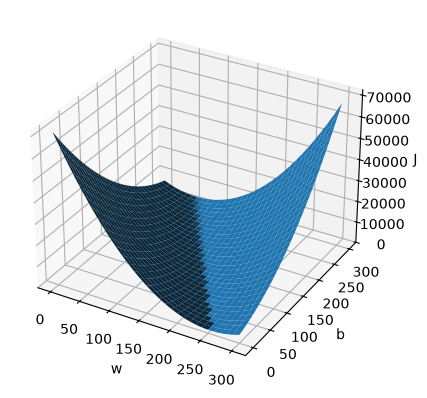

In [15]:
fig = plt.figure()
ax = fig.add_subplot(111, projection='3d')
w_values = np.arange(0, 301, 5)
b_values = np.arange(0, 301, 5)
W, B = np.meshgrid(w_values, b_values)

# Evaluate the cost at every (w, b) pair of the grid
J = np.zeros(W.shape)
for r in range(W.shape[0]):
    for c in range(W.shape[1]):
        J[r, c] = compute_cost(x_train, y_train, W[r, c], B[r, c])

ax.plot_surface(W, B, J)

ax.set_xlabel('w')
ax.set_ylabel('b')
ax.set_zlabel('J')

plt.show()

<a name="6"></a>
## 6 - Gradient descent

In this section you implement gradient descent for linear regression. Exercise 3 computes the two partial derivatives of the cost. Exercise 4 implements the update of $w$ and $b$.

As described in the lecture, the gradient descent algorithm is:

$$\begin{align*}& \text{repeat until convergence:} \; \lbrace \newline \; & \phantom {0000} b := b -  \alpha \frac{\partial J(w,b)}{\partial b} \newline       \; & \phantom {0000} w := w -  \alpha \frac{\partial J(w,b)}{\partial w}  \; &
\newline & \rbrace\end{align*}$$

where the parameters $w, b$ are both updated simultaneously and where
$$
\frac{\partial J(w,b)}{\partial b}  = \frac{1}{m} \sum\limits_{i = 1}^{m} (f_{w,b}(x^{(i)}) - y^{(i)})
$$
$$
\frac{\partial J(w,b)}{\partial w}  = \frac{1}{m} \sum\limits_{i = 1}^{m} (f_{w,b}(x^{(i)}) -y^{(i)})x^{(i)}
$$
* $m$ is the number of training examples in the dataset.


* $f_{w,b}(x^{(i)})$ is the model's prediction and $y^{(i)}$ is the target value.


You will implement a function called `compute_gradient` which calculates $\frac{\partial J(w,b)}{\partial w}$ and $\frac{\partial J(w,b)}{\partial b}$.

<a name="ex03"></a>
### Exercise 3: Gradient Descent (the gradient)

Complete the two lines marked `# TODO` inside the loop of `compute_gradient`. The prediction `f_wb_i` of example $i$ is already computed. Replace each `None` with the term of example $i$ in its sum:

* in `dj_dw`, the term $(f_{w,b}(x^{(i)}) - y^{(i)})\,x^{(i)}$,
* in `dj_db`, the term $f_{w,b}(x^{(i)}) - y^{(i)}$.

Keep the `+=`. It adds each term to its sum. The division by $m$ after the loop is given. The function then returns the two partial derivatives

$$\frac{\partial J(w,b)}{\partial w} = \frac{1}{m} \sum\limits_{i = 1}^{m} (f_{w,b}(x^{(i)}) - y^{(i)})x^{(i)}$$

$$\frac{\partial J(w,b)}{\partial b} = \frac{1}{m} \sum\limits_{i = 1}^{m} (f_{w,b}(x^{(i)}) - y^{(i)})$$

Here, $m$ is the number of training examples and $\sum$ is the summation operator.

In [16]:
def compute_gradient(x, y, w, b):
    """
    Computes the gradient for linear regression
    Args:
      x (ndarray (m,)): Data, m examples
      y (ndarray (m,)): target values
      w,b (scalar)    : model parameters
    Returns
      dj_dw (scalar): The partial derivative of the cost with respect to w
      dj_db (scalar): The partial derivative of the cost with respect to b
     """

    # Number of training examples
    m = x.shape[0]
    dj_dw = 0
    dj_db = 0

    for i in range(m):
        f_wb_i = x[i]*w + b
        dj_dw += (f_wb_i - y[i]) * x[i]
        dj_db += f_wb_i - y[i]

    dj_dw = dj_dw / m
    dj_db = dj_db / m
    return dj_dw, dj_db

Run the cells below to check your implementation of the `compute_gradient` function at two pairs of parameters, $w = 0, b = 0$ and $w = 100, b = 10$. If a line marked `# TODO` still holds `None`, Python stops with a `TypeError` about `NoneType`.

In [17]:
# Compute and display the gradient at w = 0, b = 0
initial_w = 0
initial_b = 0

tmp_dj_dw, tmp_dj_db = compute_gradient(x_train, y_train, initial_w, initial_b)
assert np.ndim(tmp_dj_dw) == 0 and np.ndim(tmp_dj_db) == 0, "compute_gradient returns an array, but each partial derivative is one number. Inside the loop, use x[i] and y[i], not x and y."
print(f'Gradient at initial w, b (zeros): {tmp_dj_dw:.4f} {tmp_dj_db:.4f}')

Gradient at initial w, b (zeros): -548.8505 -362.2395


Expected output:

    Gradient at initial w, b (zeros): -548.8505 -362.2395

In [18]:
# Compute and display the gradient at w = 100, b = 10
test_w = 100
test_b = 10
tmp_dj_dw, tmp_dj_db = compute_gradient(x_train, y_train, test_w, test_b)
assert np.ndim(tmp_dj_dw) == 0 and np.ndim(tmp_dj_db) == 0, "compute_gradient returns an array, but each partial derivative is one number. Inside the loop, use x[i] and y[i], not x and y."

print(f'Gradient at test w, b: {tmp_dj_dw:.4f} {tmp_dj_db:.4f}')

Gradient at test w, b: -317.8671 -210.8685


Expected output:

    Gradient at test w, b: -317.8671 -210.8685

In [19]:
# Check your result
tmp_dj_dw, tmp_dj_db = compute_gradient(x_train, y_train, 100, 10)
assert tmp_dj_dw is not None and tmp_dj_db is not None, "compute_gradient returns None. Complete the lines marked TODO first."
assert np.ndim(tmp_dj_dw) == 0 and np.ndim(tmp_dj_db) == 0, "compute_gradient returns an array, but each partial derivative is one number. Inside the loop, use x[i] and y[i], not x and y."
assert np.isclose(tmp_dj_dw, -317.867127, atol=1e-4) and np.isclose(tmp_dj_db, -210.86852, atol=1e-4), "compute_gradient gives the wrong values at w=100, b=10"
tmp_dj_dw, tmp_dj_db = compute_gradient(np.array([1.0, 2.0, 3.0]), np.array([2.0, 2.0, 4.0]), 1, 0)
assert np.isclose(tmp_dj_dw, -4/3) and np.isclose(tmp_dj_db, -2/3), "compute_gradient gives the wrong values on the small example"
print("Check passed")

Check passed


Expected output:

    Check passed

The second check uses the same three points as before. With $w = 1$ and $b = 0$ you can work out by hand that $\frac{\partial J(w,b)}{\partial w} = -\frac{4}{3}$ and $\frac{\partial J(w,b)}{\partial b} = -\frac{2}{3}$.

<a name="ex04"></a>
### Exercise 4: Gradient Descent (the update)


You will now use batch gradient descent to find values of $w$ and $b$ close to the minimum of $J(w,b)$. Batch means that every step uses all the training examples.

- Implement the update rule of gradient descent in the function `gradient_descent` below.

$$\begin{align*}&
\phantom {0000} b := b -  \alpha \frac{\partial J(w,b)}{\partial b} \newline       \; & \phantom {0000} w := w -  \alpha \frac{\partial J(w,b)}{\partial w}  \; &
\newline & \end{align*}$$



- A good way to verify that gradient descent is working correctly is to look
at the value of $J(w,b)$ and check that it is decreasing with each step.

- Assuming you have implemented the gradient and computed the cost correctly and you have an appropriate value for the learning rate $\alpha$, $J(w,b)$ should never increase and should converge to a steady value by the end of the algorithm.

In [20]:
def gradient_descent(x, y, w_in, b_in, cost_function, gradient_function, alpha, num_iters):
    """
    Performs batch gradient descent to learn w and b. Updates w and b by taking
    num_iters gradient steps with learning rate alpha

    Args:
      x :    (ndarray): Shape (m,)
      y :    (ndarray): Shape (m,)
      w_in, b_in : (scalar) Initial values of parameters of the model
      cost_function: function to compute cost
      gradient_function: function to compute the gradient
      alpha : (float) Learning rate
      num_iters : (int) number of iterations to run gradient descent
    Returns
      w : (scalar) Updated value of parameter of the model after
          running gradient descent
      b : (scalar) Updated value of parameter of the model after
          running gradient descent
      J_history : (list) The cost after each iteration
      w_history, b_history : (list) w and b at the start and at each printed iteration, for the plots
    """

    # number of training examples
    m = len(x)

    # Lists to store the cost J and the parameters, for the plots later
    J_history = []
    w_history = [w_in]
    b_history = [b_in]
    w = copy.deepcopy(w_in)
    b = b_in

    for i in range(num_iters):

        # Calculate the gradient at the current w and b
        dj_dw, dj_db = gradient_function(x, y, w, b )

        # Update Parameters using w, b, alpha and gradient
        w = w - alpha * dj_dw
        b = b - alpha * dj_db
        assert w is not None and b is not None, "w or b is None. Complete the lines marked TODO in gradient_descent first."

        # Save cost J at each iteration
        if i<100000:      # prevent resource exhaustion
            cost =  cost_function(x, y, w, b)
            J_history.append(cost)

        # Print the cost 10 times during the run, or at every iteration if num_iters < 10
        if i% math.ceil(num_iters/10) == 0:
            w_history.append(w)
            b_history.append(b)
            print(f"Iteration {i:4}: Cost {float(J_history[-1]):8.2f}   ")

    return w, b, J_history, w_history, b_history

Now let's run the gradient descent algorithm above to learn the parameters for our dataset. The line for iteration 0 shows the cost after the first step. That cost is already lower than the cost at the start, $J(0, 0) = 71024.09$.

Iteration    0: Cost 66766.88   
Iteration 1000: Cost  1489.92   
Iteration 2000: Cost  1457.23   


Iteration 3000: Cost  1446.26   
Iteration 4000: Cost  1442.57   
Iteration 5000: Cost  1441.34   


Iteration 6000: Cost  1440.92   
Iteration 7000: Cost  1440.78   


Iteration 8000: Cost  1440.73   
Iteration 9000: Cost  1440.72   


w,b found by gradient descent: 216.1402 56.6941


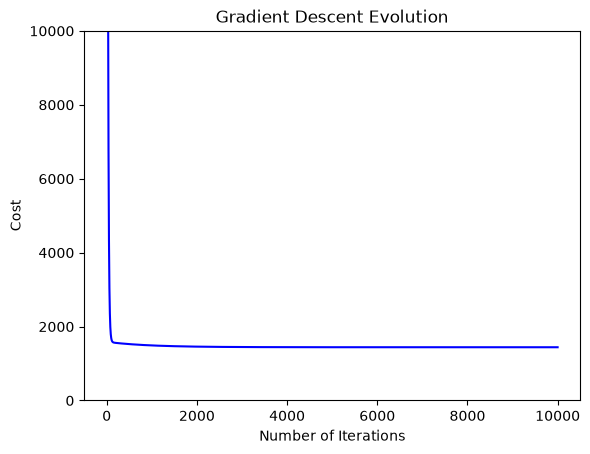

In [21]:
# initialize fitting parameters
initial_w = 0.
initial_b = 0.

# some gradient descent settings
iterations = 10000
alpha = 0.01

w_optimal,b_optimal,J_history, w_history, b_history = gradient_descent(x_train ,y_train, initial_w, initial_b,
                     compute_cost, compute_gradient, alpha, iterations)


print(f"w,b found by gradient descent: {w_optimal:.4f} {b_optimal:.4f}")

# Set the title
plt.title("Gradient Descent Evolution")
# Set the y-axis label
plt.ylabel('Cost')
plt.ylim(0,10000)
# Set the x-axis label
plt.xlabel('Number of Iterations')

# Plot the cost history
plt.plot(np.arange(0,iterations,1), J_history, c = "b")
plt.show()

Expected output:

    Iteration    0: Cost 66766.88   
    Iteration 1000: Cost  1489.92   
    Iteration 2000: Cost  1457.23   
    Iteration 3000: Cost  1446.26   
    Iteration 4000: Cost  1442.57   
    Iteration 5000: Cost  1441.34   
    Iteration 6000: Cost  1440.92   
    Iteration 7000: Cost  1440.78   
    Iteration 8000: Cost  1440.73   
    Iteration 9000: Cost  1440.72   
    w,b found by gradient descent: 216.1402 56.6941

In [22]:
# Check your result
w_1, b_1, _, _, _ = gradient_descent(np.array([1.0, 2.0, 3.0]), np.array([2.0, 2.0, 4.0]), 1., 0.,
                                     compute_cost, compute_gradient, 0.1, 1)
assert np.isclose(w_1, 1 + 0.1 * 4/3) and np.isclose(b_1, 0.1 * 2/3), "one step from w=1, b=0 with alpha=0.1 gives the wrong w and b"
assert np.isclose(w_optimal, 216.1402, atol=1e-3) and np.isclose(b_optimal, 56.6941, atol=1e-3), "gradient descent does not reach the expected w and b"
assert np.all(np.diff(J_history) <= 1e-9), "the cost should never increase with alpha = 0.01"
print("Check passed")

Iteration    0: Cost     0.17   
Check passed


Expected output:

    Iteration    0: Cost     0.17   
    Check passed

The first check runs one step of gradient descent on the three small points, from $w = 1$ and $b = 0$ with $\alpha = 0.1$. By hand, $w := 1 - 0.1 \cdot (-\frac{4}{3}) \approx 1.1333$ and $b := 0 - 0.1 \cdot (-\frac{2}{3}) \approx 0.0667$. The first line of the expected output comes from that step. It is the cost after the step, 0.17, down from $\frac{1}{3}$ before it.

### Try it: the learning rate

This part is optional. The cell below runs gradient descent for 100 iterations with $\alpha = 1$, $\alpha = 0.5$ and $\alpha = 0.01$. Look at the printed cost. If it grows from one line to the next, gradient descent diverges. With a very large $\alpha$ the cost can become `inf` or `nan`. This also means that gradient descent diverges.

Change the values in the list to find the largest $\alpha$ that still converges. Look for it with two decimals, for example 0.60, 0.61 and 0.62. Write it in `largest_alpha`.

In [23]:
# Try it (optional): change the values in this list and run the cell again
for alpha_try in [1, 0.5, 0.01]:
    print(f"alpha = {alpha_try}")
    gradient_descent(x_train, y_train, 0., 0., compute_cost, compute_gradient, alpha_try, 100)
    print()

largest_alpha = 0.64  # 0.64 still converges and 0.65 diverges (the exact limit is about 0.642)

alpha = 1
Iteration    0: Cost 311856.12   
Iteration   10: Cost 985074901394.53   
Iteration   20: Cost 3127366422058160128.00   
Iteration   30: Cost 9928606178778213752242176.00   
Iteration   40: Cost 31520841292526919263675364671488.00   
Iteration   50: Cost 100070787167724672807105907560653258752.00   
Iteration   60: Cost 317699719732488183532333396113915761443995648.00   
Iteration   70: Cost 1008617147668994671602400494120569852497582784249856.00   
Iteration   80: Cost 3202107170344808118770069111441366751534859230666620403712.00   
Iteration   90: Cost 10165889360566991748708520284699593384447320644712435999198674944.00   

alpha = 0.5
Iteration    0: Cost 23118.52   
Iteration   10: Cost  1520.74   
Iteration   20: Cost  1486.63   
Iteration   30: Cost  1467.12   
Iteration   40: Cost  1455.90   
Iteration   50: Cost  1449.45   
Iteration   60: Cost  1445.74   
Iteration   70: Cost  1443.60   
Iteration   80: Cost  1442.37   
Iteration   90: Cost  1441.67   

alpha = 0.01


### Inspecting behaviour of Gradient Descent

The plot below draws the line at the start, after the first step and then every 1,000 iterations. Lighter lines come earlier and darker lines later.

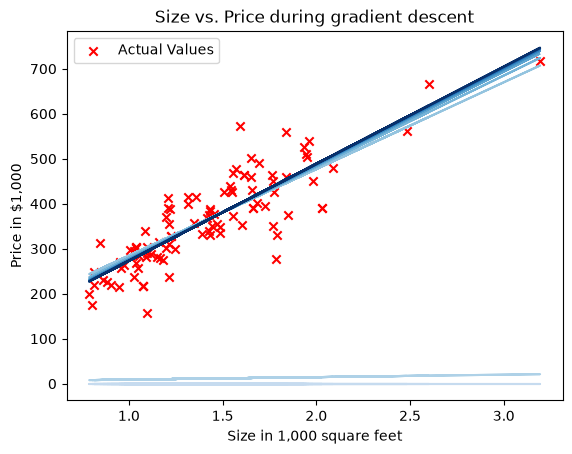

In [24]:
# Draw the line at the start, after the first step and then every 1,000 iterations,
# from light (early) to dark (late)
colors = plt.cm.Blues(np.linspace(0.25, 1, len(w_history)))
for k, (w_t, b_t) in enumerate(zip(w_history, b_history)):
    tmp_f_wb = compute_model_output(x_train, w_t, b_t)
    plt.plot(x_train, tmp_f_wb, color=colors[k])

# Plot the data points
plt.scatter(x_train, y_train, marker='x', c='r', label='Actual Values')

# Set the title
plt.title("Size vs. Price during gradient descent")
# Set the y-axis label
plt.ylabel('Price in $1,000')
# Set the x-axis label
plt.xlabel('Size in 1,000 square feet')
plt.legend()
plt.show()

### Making Predictions

We will now use the final parameters from gradient descent to plot the linear fit.

Recall that we can get the prediction for a single example $f_{w,b}(x^{(i)})= wx^{(i)}+b$.

Your `compute_model_output` from Exercise 1 loops over the training examples and computes the prediction for each one. The cell below calls it with the final $w$ and $b$.

In [25]:
predicted = compute_model_output(x_train, w_optimal, b_optimal)

We will now plot the predicted values to see the linear fit.

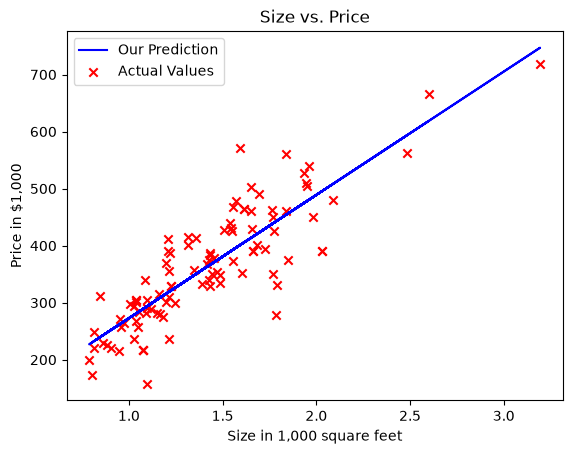

In [26]:
# Plot the linear fit
plt.plot(x_train, predicted, c = "b",label='Our Prediction')

# Create a scatter plot of the data.
plt.scatter(x_train, y_train, marker='x', c='r', label='Actual Values')

# Set the title
plt.title("Size vs. Price")
# Set the y-axis label
plt.ylabel('Price in $1,000')
# Set the x-axis label
plt.xlabel('Size in 1,000 square feet')
plt.legend()
plt.show()


Your final values of $w,b$ can also be used to make predictions on prices. Let's predict what the price would be for houses with sizes of 1000 and 2000 square feet.

- The model takes in the size of the house in 1,000 square feet as input.
- Therefore, a size of 1000 square feet can be translated into an input to the model as `1`.
- Similarly, a size of 2000 square feet can be translated into an input to the model as `2`.


In [27]:
predict1 = 1 * w_optimal + b_optimal
print('For area = 1,000 we predict a price of $%.0f' % (predict1*1000))

predict2 = 2 * w_optimal + b_optimal
print('For area = 2,000 we predict a price of $%.0f' % (predict2*1000))

For area = 1,000 we predict a price of $272834
For area = 2,000 we predict a price of $488975


Expected output:

    For area = 1,000 we predict a price of $272834
    For area = 2,000 we predict a price of $488975